In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    SimpleRNN,
    LSTM,
    Bidirectional,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
vocab_size = 10000

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Train samples:", len(x_train))
print("Test samples:", len(x_test))

print("Example review:", x_train[0][:20])
print("Sentiment:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train samples: 25000
Test samples: 25000
Example review: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
Sentiment: 1


In [3]:
max_length = 200

x_train = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Train shape:", x_train.shape)
print("Test shape:", x_test.shape)

Train shape: (25000, 200)
Test shape: (25000, 200)


In [5]:
rnn_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    SimpleRNN(64),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

rnn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=1,
        min_lr=0.00001
    )
]

history_rnn = rnn_model.fit(
    x_train,
    y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.2,
    callbacks=callbacks
)

Epoch 1/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 13s 44ms/step - accuracy: 0.5236 - loss: 0.6922 - val_accuracy: 0.6536 - val_loss: 0.6434 - learning_rate: 0.0010
Epoch 2/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.6866 - loss: 0.5963 - val_accuracy: 0.6198 - val_loss: 0.6431 - learning_rate: 0.0010
Epoch 3/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.8072 - loss: 0.4342 - val_accuracy: 0.5706 - val_loss: 0.7543 - learning_rate: 0.0010
Epoch 4/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9032 - loss: 0.2536 - val_accuracy: 0.7880 - val_loss: 0.5492 - learning_rate: 5.0000e-04
Epoch 5/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9773 - loss: 0.0734 - val_accuracy: 0.7314 - val_loss: 0.8011 - learning_rate: 5.0000e-04
Epoch 6/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9966 - loss: 0.0200 - val_accuracy: 0.7372 - val_loss: 0.8290 - learning_rate: 2.5000e-04


In [7]:
rnn_loss, rnn_accuracy = rnn_model.evaluate(
    x_test,
    y_test
)

print(f"SimpleRNN Accuracy: {rnn_accuracy * 100:.2f}%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7785 - loss: 0.5827
SimpleRNN Accuracy: 77.85%


In [8]:
lstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(64),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [9]:
history_lstm = lstm_model.fit(
    x_train,
    y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=2,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=1,
            min_lr=0.00001
        )
    ]
)

Epoch 1/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.7099 - loss: 0.5333 - val_accuracy: 0.7970 - val_loss: 0.4430 - learning_rate: 0.0010
Epoch 2/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8860 - loss: 0.2909 - val_accuracy: 0.8458 - val_loss: 0.3506 - learning_rate: 0.0010
Epoch 3/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9153 - loss: 0.2230 - val_accuracy: 0.8634 - val_loss: 0.3462 - learning_rate: 0.0010
Epoch 4/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.9403 - loss: 0.1657 - val_accuracy: 0.8526 - val_loss: 0.3894 - learning_rate: 0.0010
Epoch 5/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9676 - loss: 0.0974 - val_accuracy: 0.8580 - val_loss: 0.4946 - learning_rate: 5.0000e-04


In [10]:
lstm_loss, lstm_accuracy = lstm_model.evaluate(
    x_test,
    y_test
)

print(f"LSTM Accuracy: {lstm_accuracy * 100:.2f}%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8412 - loss: 0.4011
LSTM Accuracy: 84.12%


In [11]:
bilstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    Bidirectional(
        LSTM(64)
    ),

    Dropout(0.4),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

bilstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

bilstm_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [12]:
history_bilstm = bilstm_model.fit(
    x_train,
    y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=2,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=1,
            min_lr=0.00001
        )
    ]
)

Epoch 1/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.6834 - loss: 0.5631 - val_accuracy: 0.8416 - val_loss: 0.3683 - learning_rate: 0.0010
Epoch 2/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.8864 - loss: 0.2788 - val_accuracy: 0.8732 - val_loss: 0.3066 - learning_rate: 0.0010
Epoch 3/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9313 - loss: 0.1877 - val_accuracy: 0.8660 - val_loss: 0.3420 - learning_rate: 0.0010
Epoch 4/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9639 - loss: 0.1126 - val_accuracy: 0.8694 - val_loss: 0.3843 - learning_rate: 5.0000e-04


In [13]:
bilstm_loss, bilstm_accuracy = bilstm_model.evaluate(
    x_test,
    y_test
)

print(
    f"Bidirectional LSTM Accuracy: "
    f"{bilstm_accuracy * 100:.2f}%"
)

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8535 - loss: 0.3343
Bidirectional LSTM Accuracy: 85.35%


In [14]:
deep_lstm_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(
        64,
        return_sequences=True
    ),

    Dropout(0.3),

    LSTM(32),

    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')
])

deep_lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

deep_lstm_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [15]:
history_deep = deep_lstm_model.fit(
    x_train,
    y_train,
    epochs=8,
    batch_size=128,
    validation_split=0.2,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=2,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=1,
            min_lr=0.00001
        )
    ]
)

Epoch 1/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.7499 - loss: 0.4974 - val_accuracy: 0.8480 - val_loss: 0.3745 - learning_rate: 0.0010
Epoch 2/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.8893 - loss: 0.2892 - val_accuracy: 0.8656 - val_loss: 0.3356 - learning_rate: 0.0010
Epoch 3/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9176 - loss: 0.2276 - val_accuracy: 0.8622 - val_loss: 0.3420 - learning_rate: 0.0010
Epoch 4/8
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9557 - loss: 0.1374 - val_accuracy: 0.8636 - val_loss: 0.3967 - learning_rate: 5.0000e-04


In [16]:
deep_loss, deep_accuracy = deep_lstm_model.evaluate(
    x_test,
    y_test
)

print(
    f"Deep LSTM Accuracy: "
    f"{deep_accuracy * 100:.2f}%"
)

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8486 - loss: 0.3636
Deep LSTM Accuracy: 84.86%


In [17]:
results = pd.DataFrame({
    'Model': [
        'SimpleRNN',
        'LSTM',
        'Bidirectional LSTM',
        'Deep LSTM'
    ],

    'Test Accuracy': [
        rnn_accuracy,
        lstm_accuracy,
        bilstm_accuracy,
        deep_accuracy
    ]
})

results['Accuracy (%)'] = (
    results['Test Accuracy'] * 100
)

results = results.sort_values(
    by='Test Accuracy',
    ascending=False
)

display(results)

,Model,Test Accuracy,Accuracy (%)
2,Bidirectional LSTM,0.85352,85.351998
3,Deep LSTM,0.84864,84.864002
1,LSTM,0.84116,84.116000
0,SimpleRNN,0.77852,77.851999


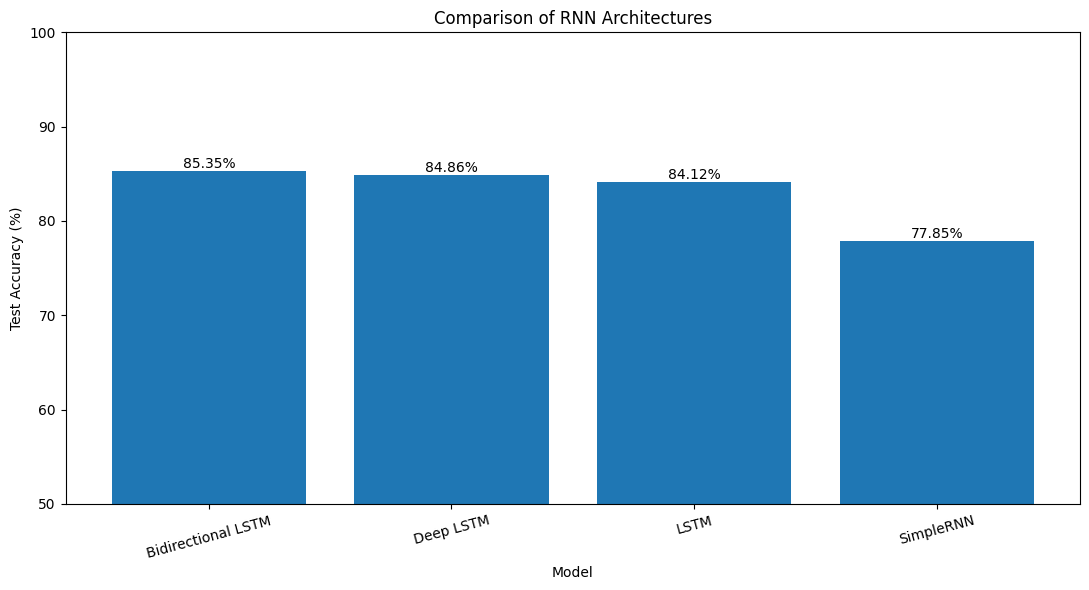

In [18]:
plt.figure(figsize=(11, 6))

bars = plt.bar(
    results['Model'],
    results['Accuracy (%)']
)

plt.title('Comparison of RNN Architectures')
plt.xlabel('Model')
plt.ylabel('Test Accuracy (%)')
plt.ylim(50, 100)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.3,
        f'{height:.2f}%',
        ha='center'
    )

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

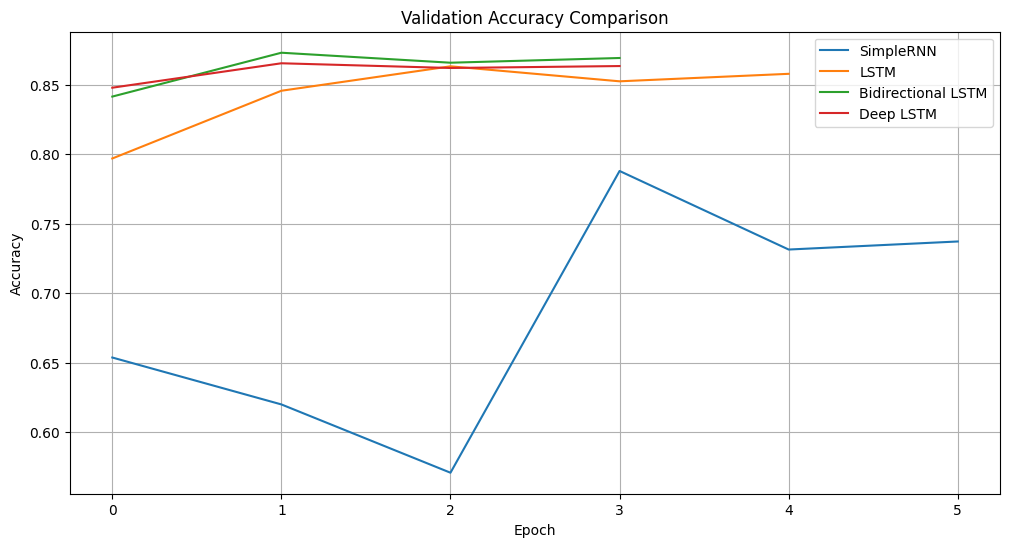

In [19]:
histories = {
    'SimpleRNN': history_rnn,
    'LSTM': history_lstm,
    'Bidirectional LSTM': history_bilstm,
    'Deep LSTM': history_deep
}

plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(
        history.history['val_accuracy'],
        label=name
    )

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [20]:
best_model = results.iloc[0]

print("Best model:", best_model['Model'])
print(
    f"Best accuracy: "
    f"{best_model['Accuracy (%)']:.2f}%"
)

Best model: Bidirectional LSTM
Best accuracy: 85.35%


Висновок: Найкращою в межах проведених експериментів виявилася модель Bidirectional LSTM з точністю 85,35%.